<a href="https://colab.research.google.com/github/jayavenkatasai224/ITA0514-Computer-Vision/blob/main/ex_no_30.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Smiling Trio in a Green Campus Setting.png to Smiling Trio in a Green Campus Setting (5).png
Number of Faces: 6
Number of Smiles Detected: 6
Smile Detection Output


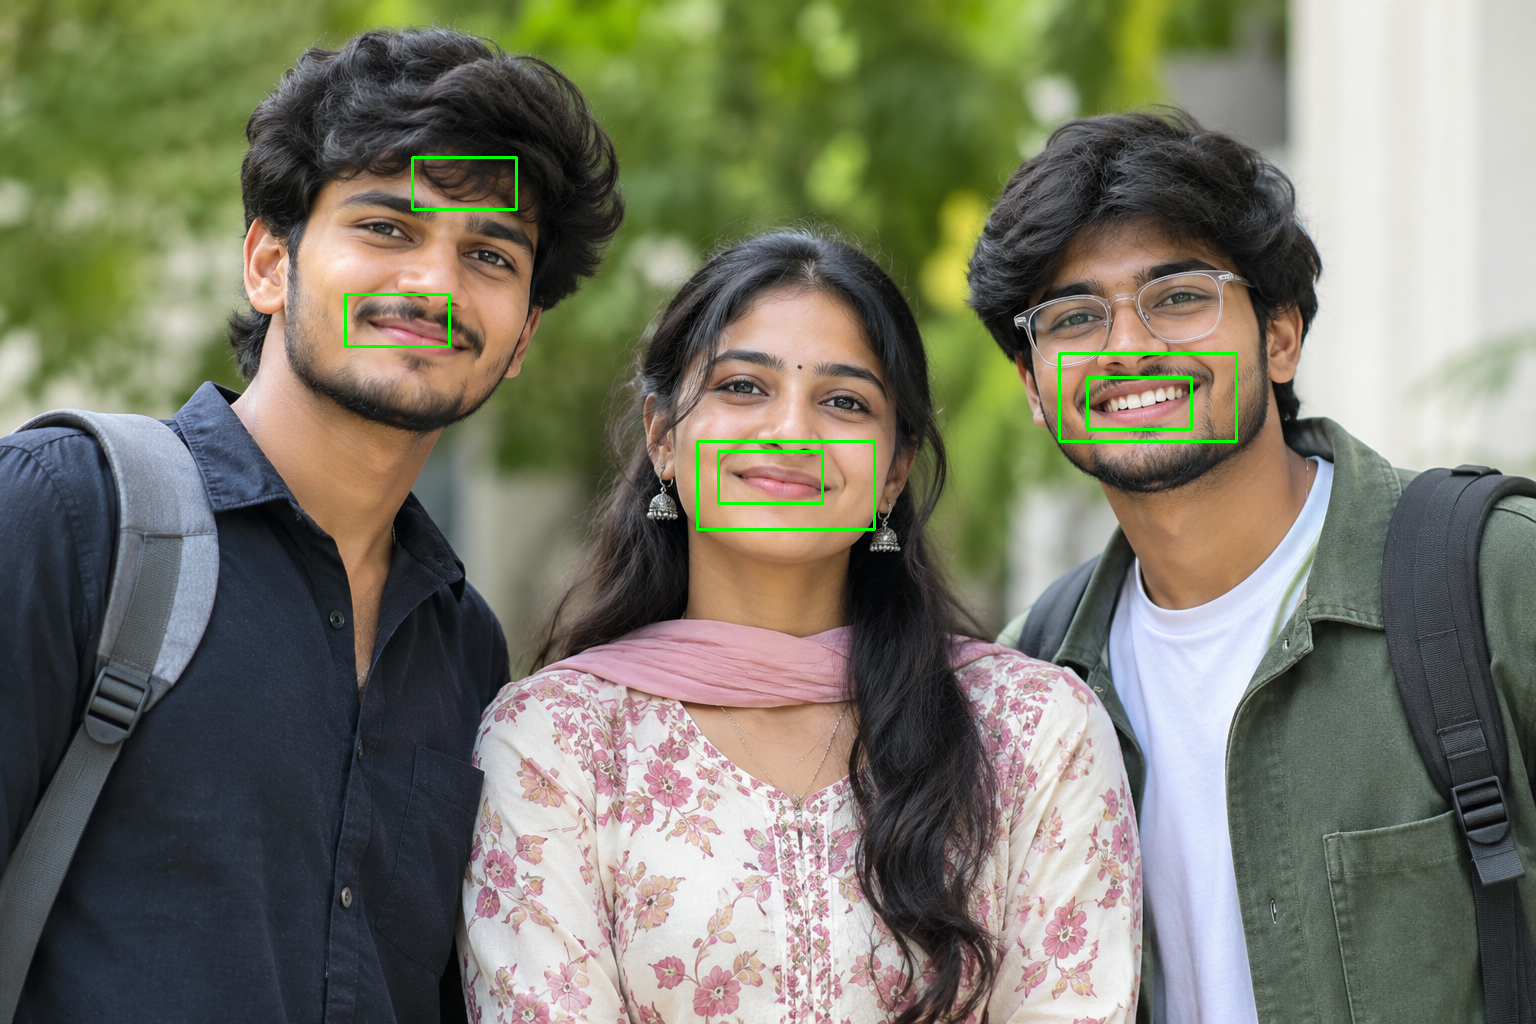

In [4]:

import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload image
uploaded = files.upload()

# Read uploaded image
filename = next(iter(uploaded))
img = cv2.imread(filename)

if img is None:
    print("Image not found")
else:
    # Convert image to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Load Haar Cascade classifiers
    face_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades +
        "haarcascade_frontalface_default.xml"
    )

    smile_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades +
        "haarcascade_smile.xml"
    )

    # Detect faces
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5
    )

    smile_count = 0

    # Detect smiles inside each face
    for (x, y, w, h) in faces:
        roi_gray = gray[y:y+h, x:x+w]
        roi_color = img[y:y+h, x:x+w]

        # Detect smiles
        smiles = smile_cascade.detectMultiScale(
            roi_gray,
            scaleFactor=1.7,
            minNeighbors=20,
            minSize=(25, 15)
        )

        # Draw rectangles around smiles
        for (sx, sy, sw, sh) in smiles:
            cv2.rectangle(
                roi_color,
                (sx, sy),
                (sx+sw, sy+sh),
                (0, 255, 0),
                2
            )
            smile_count += 1

    # Display output
    print("Number of Faces:", len(faces))
    print("Number of Smiles Detected:", smile_count)
    print("Smile Detection Output")
    cv2_imshow(img)
